In [1]:
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
from sklearn.metrics import root_mean_squared_error
import numpy as np

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv("manufacturing.csv")

In [4]:
df.corr()

,Temperature (°C),Pressure (kPa),Temperature x Pressure,Material Fusion Metric,Material Transformation Metric,Quality Rating
Temperature (°C),1.000000,-0.024754,0.571743,0.974901,0.971210,-0.461279
Pressure (kPa),-0.024754,1.000000,0.773572,0.151095,-0.022862,0.013129
Temperature x Pressure,0.571743,0.773572,1.000000,0.694733,0.555579,-0.258474
Material Fusion Metric,0.974901,0.151095,0.694733,1.000000,0.976708,-0.511972
Material Transformation Metric,0.971210,-0.022862,0.555579,0.976708,1.000000,-0.575756
Quality Rating,-0.461279,0.013129,-0.258474,-0.511972,-0.575756,1.000000


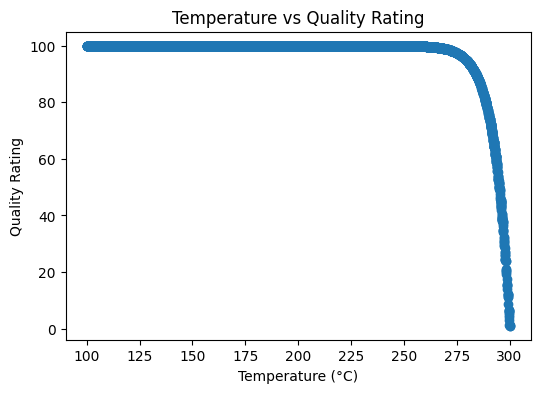

In [ ]:
x = df[["Temperature (°C)"]]   
y = df["Quality Rating"]

plt.figure(figsize=(6,4))
plt.scatter(x, y)
plt.xlabel("Temperature (°C)")
plt.ylabel("Quality Rating")
plt.title("Temperature vs Quality Rating")
plt.show()

In [13]:
xtrain,xtest,ytrain,ytest = train_test_split(x,y,train_size=0.8,random_state=42)

In [14]:
model = LinearRegression()
model.fit(xtrain,ytrain)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [15]:
#model evaluvation
ytrain_pred = model.predict(xtrain)
train_score = r2_score(ytrain,ytrain_pred) 
print(f'train Score {train_score}')

train Score 0.21210926738525993


In [16]:
#test data
ytest_pred = model.predict(xtest)
test_score = r2_score(ytest,ytest_pred) 
print(f'test Score {test_score}')

test Score 0.2132660374568569


**Observation: here model performance is bad because we are using non-linear dataset for linear regression**

In [17]:
from sklearn.preprocessing import PolynomialFeatures


In [18]:
poly = PolynomialFeatures(degree=2)

In [19]:
updated_xtrain = poly.fit_transform(xtrain)

In [21]:
updated_xtest = poly.transform(xtest)

In [20]:
model_poly = LinearRegression()

In [23]:
model_poly.fit(updated_xtrain,ytrain)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [25]:
#model evaluvation
ytrain_pred = model_poly.predict(updated_xtrain)
train_score = r2_score(ytrain,ytrain_pred) 
print(f'train Score {train_score}')

#test data
ytest_pred = model_poly.predict(updated_xtest)
test_score = r2_score(ytest,ytest_pred) 
print(f'test Score {test_score}')

train Score 0.4578009195259306
test Score 0.4697918263612709


In [32]:
poly = PolynomialFeatures(degree=4)
updated_xtrain1 = poly.fit_transform(updated_xtrain)
updated_xtest1 = poly.transform(updated_xtest)
model_poly1 = LinearRegression()
model_poly1.fit(updated_xtrain1,ytrain)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [33]:
#model evaluvation
ytrain_pred = model_poly1.predict(updated_xtrain1)
train_score = r2_score(ytrain,ytrain_pred) 
print(f'train Score {train_score}')

#test data
ytest_pred = model_poly1.predict(updated_xtest1)
test_score = r2_score(ytest,ytest_pred) 
print(f'test Score {test_score}')

train Score 0.9444634840731236
test Score 0.9469365312012668


In [36]:
poly = PolynomialFeatures(degree=6)
updated_xtrain2 = poly.fit_transform(updated_xtrain)  
updated_xtest2 = poly.transform(updated_xtest)

model_poly2 = LinearRegression()
model_poly2.fit(updated_xtrain2, ytrain)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [37]:
#model evaluvation
ytrain_pred = model_poly2.predict(updated_xtrain2)
train_score = r2_score(ytrain,ytrain_pred) 
print(f'train Score {train_score}')

#test data
ytest_pred = model_poly2.predict(updated_xtest2)
test_score = r2_score(ytest,ytest_pred) 
print(f'test Score {test_score}')

train Score 0.9864267877422912
test Score 0.9874498425050703


**Observation: here model performance is good because by increasing the degree we increse complexity of a model which helps to learn complex patterns**